<a href="https://colab.research.google.com/github/SithmiDesilva/Voices-on-School-Reform-An-NLP-Analysis-of-Sri-Lankan-YouTube-Comments/blob/Data-collection-and-EDA/Voices_on_School_Reform_An_NLP_Analysis_of_Sri_Lankan_YouTube_Comments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Imports and Versions

In [1]:
import os, re, json, time, random, hashlib, math
from datetime import datetime, timezone
from pathlib import Path
from collections import Counter
from importlib.metadata import version
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import warnings
warnings.filterwarnings('ignore', message='.*(Glyph|does not support Sinhala).*')

SEED = 42
random.seed(SEED); np.random.seed(SEED)

pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

print('Python                  ', sys.version.split()[0])
print('pandas                  ', pd.__version__)
print('numpy                   ', np.__version__)
print('matplotlib              ', matplotlib.__version__)
print('scikit-learn            ', sklearn.__version__)
print('google-api-python-client', version('google-api-python-client'))

Python                   3.13.16
pandas                   2.2.3
numpy                    2.4.6
matplotlib               3.10.0
scikit-learn             1.6.1
google-api-python-client 2.201.0


### Mount Google drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/NLP_CW')
RAW_DIR  = BASE_DIR / 'data' / 'raw'
CKPT_DIR = RAW_DIR / 'comments_by_video'      # one JSON per video (checkpoint)
FIG_DIR  = BASE_DIR / 'figures'
for d in (RAW_DIR, CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print(BASE_DIR)

Mounted at /content/drive
/content/drive/MyDrive/NLP_CW


### API client

In [3]:
from google.colab import userdata
YT_API_KEY = userdata.get('YT_API_KEY')
youtube = build('youtube', 'v3', developerKey=YT_API_KEY, cache_discovery=False)

try:
    AUTHOR_SALT = userdata.get('AUTHOR_SALT')
except Exception:
    AUTHOR_SALT = 'change-me-and-store-in-secrets'
print('YouTube client ready')

YouTube client ready


### Search queries and settings

In [4]:
SEARCH_QUERIES = {
    'en': [
        'Sri Lanka education reform',
        'Sri Lanka new education reforms 2026',
        'Sri Lanka school curriculum change',
        'Sri Lanka O/L A/L exam reform',
        'Sri Lanka grade 1 grade 6 new curriculum',
        'Sri Lanka education reform teachers',
        'Sri Lanka modular education system school',
        'Sri Lanka vocational education schools reform',
        'Sri Lanka digital education schools',
        'Sri Lanka history subject removed curriculum',
        'Sri Lanka education minister reform debate',
    ],
    'si': [
        'අධ්‍යාපන ප්‍රතිසංස්කරණ',
        'නව අධ්‍යාපන ප්‍රතිසංස්කරණ',
        'අධ්‍යාපන ප්‍රතිසංස්කරණ ගුරුවරු',
        'නව විෂය නිර්දේශය පාසල්',
        'සාමාන්‍ය පෙළ උසස් පෙළ වෙනස්කම්',
        '6 ශ්‍රේණිය මොඩියුල',
        'පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ',
        'adyapana prathisanskarana',       # romanised Sinhala ("Singlish")
    ],
}

PUBLISHED_AFTER = '2024-01-01T00:00:00Z'   # current reform cycle
REGION_CODE = 'LK'
RESULTS_PER_QUERY = 25          # max 50 per search call
MIN_COMMENT_COUNT = 15          # skip videos with very few comments
MAX_COMMENTS_PER_VIDEO = 800    # per-video ceiling (30% rule applied later)
INCLUDE_REPLIES = True
FETCH_ALL_REPLIES = True        # commentThreads gives only 5 inline replies; fetch the rest
COMMENT_ORDER = 'time'          # avoids YouTube's relevance ranking
MAX_VIDEO_SHARE = 0.30
TARGET_MIN_COMMENTS = 3000

RELEVANCE_KEYWORDS = [
    'education', 'reform', 'curriculum', 'syllabus', 'school', 'exam', 'o/l', 'a/l', 'grade', 'teacher',
    'module', 'vocational', 'student',
    'අධ්‍යාපන', 'ප්‍රතිසංස්කරණ', 'විෂය', 'පාසල', 'ගුරු', 'ශ්‍රේණිය', 'පෙළ', 'විභාග', 'මොඩියුල', 'සිසු',
]
SRI_LANKA_KEYWORDS = ['sri lanka', 'srilanka', 'lanka', 'ශ්‍රී ලංකා', 'ලංකා', 'harini', 'හරිනි']

COLLECTION_DATE = datetime.now(timezone.utc).isoformat()
print('Total queries:', sum(len(v) for v in SEARCH_QUERIES.values()))

Total queries: 19


### Quota-aware API wrapper

In [5]:
QUOTA_COST = {'search': 100, 'videos': 1, 'commentThreads': 1, 'comments': 1}
quota_used = Counter()

class QuotaExceeded(Exception):
    pass

def http_reason(e):
    try:
        return json.loads(e.content.decode())['error']['errors'][0]['reason']
    except Exception:
        return f'http_{getattr(e.resp, "status", "unknown")}'

def api_call(request, kind, max_retries=4):
    for attempt in range(max_retries):
        try:
            resp = request.execute()
            quota_used[kind] += QUOTA_COST[kind]
            return resp
        except HttpError as e:
            quota_used[kind] += QUOTA_COST[kind]
            reason = http_reason(e)
            if reason in ('quotaExceeded', 'dailyLimitExceeded'):
                raise QuotaExceeded(reason)
            if e.resp.status in (500, 502, 503, 504) and attempt < max_retries - 1:
                time.sleep(2 ** attempt)
                continue
            raise

def quota_total():
    return sum(quota_used.values())

### Search for videos (results cached to Drive)

In [6]:
SEARCH_CACHE = RAW_DIR / 'search_cache.json'
search_cache = json.loads(SEARCH_CACHE.read_text()) if SEARCH_CACHE.exists() else {}

def search_videos(query, lang):
    key = f'{lang}|{query}'
    if key in search_cache:
        return search_cache[key]
    req = youtube.search().list(
        q=query, part='snippet', type='video', maxResults=min(RESULTS_PER_QUERY, 50),
        regionCode=REGION_CODE, relevanceLanguage=lang,
        publishedAfter=PUBLISHED_AFTER, order='relevance')
    resp = api_call(req, 'search')
    rows = [{
        'query': query, 'query_lang': lang,
        'video_id': it['id']['videoId'],
        'title': it['snippet']['title'],
        'channel_id': it['snippet']['channelId'],
        'channel_title': it['snippet']['channelTitle'],
        'video_published_at': it['snippet']['publishedAt'],
        'searched_at': datetime.now(timezone.utc).isoformat(),
    } for it in resp.get('items', [])]
    search_cache[key] = rows
    SEARCH_CACHE.write_text(json.dumps(search_cache, ensure_ascii=False, indent=1))
    return rows

hits = []
for lang, queries in SEARCH_QUERIES.items():
    for q in queries:
        hits.extend(search_videos(q, lang))

search_df = pd.DataFrame(hits)
print(f'{len(search_df)} hits, {search_df.video_id.nunique()} unique videos, quota used: {quota_total()}')
search_df.groupby('query_lang').video_id.nunique()

475 hits, 306 unique videos, quota used: 0


,video_id
query_lang,
en,197
si,121


### Video details (comment counts, descriptions)


In [7]:
cand = (search_df.groupby('video_id')
        .agg(title=('title', 'first'), channel_id=('channel_id', 'first'),
             channel_title=('channel_title', 'first'), video_published_at=('video_published_at', 'first'),
             matched_queries=('query', lambda s: ' || '.join(sorted(set(s)))),
             query_langs=('query_lang', lambda s: ','.join(sorted(set(s)))))
        .reset_index())

details = []
ids = cand.video_id.tolist()
for i in range(0, len(ids), 50):
    resp = api_call(youtube.videos().list(part='snippet,statistics', id=','.join(ids[i:i+50])), 'videos')
    for it in resp.get('items', []):
        st, sn = it.get('statistics', {}), it['snippet']
        details.append({
            'video_id': it['id'],
            'description': sn.get('description', ''),
            'tags': '|'.join(sn.get('tags', [])),
            'default_audio_language': sn.get('defaultAudioLanguage'),
            'view_count': int(st.get('viewCount', 0)),
            'comment_count': int(st['commentCount']) if 'commentCount' in st else None,  # missing = disabled
        })
videos = cand.merge(pd.DataFrame(details), on='video_id', how='left')
print('Videos with comments disabled/unavailable:', videos.comment_count.isna().sum())

Videos with comments disabled/unavailable: 11


### Relevance filter and manual review

In [33]:
def kw_hits(text, kws):
    t = str(text).lower()
    return sum(k.lower() in t for k in kws)

meta_text = videos.title.fillna('') + ' ' + videos.description.fillna('') + ' ' + videos.tags.fillna('')
videos['topic_kw_hits'] = meta_text.apply(lambda t: kw_hits(t, RELEVANCE_KEYWORDS))
videos['lk_kw_hits'] = meta_text.apply(lambda t: kw_hits(t, SRI_LANKA_KEYWORDS))
videos['local_query'] = videos.query_langs.str.contains('si')

videos['exclusion_reason'] = np.select(
    [videos.comment_count.isna(),
     videos.comment_count < MIN_COMMENT_COUNT,
     videos.topic_kw_hits == 0,
     (videos.lk_kw_hits == 0) & ~videos.local_query],
    ['comments_disabled_or_unavailable', 'too_few_comments', 'no_topic_keywords', 'not_sri_lanka'],
    default='')
videos['auto_include'] = videos.exclusion_reason == ''

# ---- Manual review: fill in after reading the titles below ----
MANUAL_EXCLUDE = {
    # Unrelated topic
    '4ii1rkZDhgI': 'geography/identity topic, not school reform',
    'j42KPskCsc0': 'motivational video (bad habits), not education reform',
    'K9yjfbOISnM': 'driving licence renewal, unrelated',
    'bzTQMZalVtM': 'Indian UPSC/degree debate, not Sri Lankan schools',
    # School rankings
    'h9nL4RwNAEE': 'school ranking (top 10 schools), not reform',
    'k7Y15uXnD_Y': 'school ranking (top 10 mixed schools), not reform',
    'C0ypaTw172w': 'school ranking (top 10 boys schools), not reform',
    'D9m0gq1sqcc': 'A/L subject ranking and results date, not reform',
    # Exam / certificate administration guides
    '1mGozsjkLYQ': 'how-to: A/L private application',
    'JwMy5pCk6i4': 'how-to: ordering result sheets',
    'hoUH6bmB9a8': 'how-to: certificate attestation',
    'NKp9ZXhANAU': 'how-to: certifying result sheets',
    'sCltsoIY0uY': 'how-to: downloading exam admission',
    'ZWP_SEiG21g': 'how-to: ordering certificates online',
    'A1RE63CYzH0': 'how-to: requesting certificates online',
    'xXCAP3jTeTo': 'how-to: certificate name correction',
    'P-0fBG3UaHM': 'how-to: Grade 1 admission application',
    'n4Pyhh_rg9M': 'A/L results release date announcement',
    'aRrFmhye2LE': 'O/L cut-off marks announcement',
    'JKwozF7VpTE': 'exam dates announcement',
    'SZ6tlaRiuPE': 'timetable software demo; comments request the software',
    'QcYm2EKhrC4': 'London vs national syllabus comparison; comments are contact requests',
    # Lessons (comments are thanks / class enquiries, not reform opinions)
    '-0pCTULWg8g': 'Grade 1 class promotion; comments are joining enquiries',
    'uHp107rDADk': 'Grade 6 module lesson',
    'aawhznhUzpU': 'Grade 6 module lesson',
    'xZ4WdYC_0qI': 'Grade 6 science lesson',
    'gC21s_wddnw': 'Grade 6 maths lesson',
    'o9l47fQZ6xI': 'Grade 6 maths lesson',
    'Fbw7Hg7s738': 'Grade 6 maths lesson',
    'BhQXKHDbNIs': 'Grade 6 English syllabus PDF download',
    'Xw0JGgmYHMc': 'Grade 1 Buddhism lesson',
    'i6jJgdZ8lvc': 'Sinhala grammar lesson',
    # Teaching-exam preparation (reforms as quiz content; comments are quiz answers)
    'ZYeuMI3SQzw': 'teaching-exam GK quiz on reforms; comments are quiz answers',
    'ioOFm7cYB7M': 'teaching-exam GK quiz on reforms; comments are quiz answers',
    'R9Onitso-Ic': 'teaching-exam preparation',
    'oVJKFQP9G6A': 'teaching-exam preparation',
    'mTKTus6XaWA': 'teaching-exam preparation (history of education)',
    # Tamil-medium videos (outside the Sinhala/English language scope)
    'FKoS8yJOKWo': 'Tamil-medium video; outside Sinhala/English scope',
    'sBUhUSix0qY': 'Tamil-medium video; outside Sinhala/English scope',
    'QQGkW9hedpU': 'Tamil-medium video; outside Sinhala/English scope',
    'spXSrrGSXuY': 'Tamil-medium video; outside Sinhala/English scope',
}
MANUAL_INCLUDE = {}   # {'videoId': 'reason'}
# ---------------------------------------------------------------
videos['include'] = videos.auto_include
for vid, why in MANUAL_EXCLUDE.items():
    videos.loc[videos.video_id == vid, ['include', 'exclusion_reason']] = [False, f'manual: {why}']
for vid, why in MANUAL_INCLUDE.items():
    videos.loc[videos.video_id == vid, ['include', 'exclusion_reason']] = [True, f'manual include: {why}']

videos.to_csv(RAW_DIR / 'videos_candidates.csv', index=False)
print(videos.exclusion_reason.replace('', 'included').value_counts(), "")
print('Included videos:', videos.include.sum(), '| channels:', videos.loc[videos.include, 'channel_id'].nunique())
videos.loc[videos.include, ['video_id', 'channel_title', 'title', 'comment_count', 'video_published_at']] \
      .sort_values('comment_count', ascending=False)

exclusion_reason
too_few_comments                                                                 195
included                                                                          32
not_sri_lanka                                                                     18
comments_disabled_or_unavailable                                                  11
no_topic_keywords                                                                  9
manual: Tamil-medium video; outside Sinhala/English scope                          4
manual: Grade 6 maths lesson                                                       3
manual: Grade 6 module lesson                                                      2
manual: teaching-exam preparation                                                  2
manual: teaching-exam GK quiz on reforms; comments are quiz answers                2
manual: Grade 1 class promotion; comments are joining enquiries                    1
manual: how-to: requesting certificates online  

,video_id,channel_title,title,comment_count,video_published_at
75,F-DLnJM7jpg,Ada Derana,"O/L, A/L සහ ශිෂ්‍යත්ව විභාගය ගැන දැනුම්දීමක් | Ada Derana",1030.0,2026-06-24T10:37:50Z
141,RHfwHM3M9Fc,Ada Derana,අධ්‍යාපන ප්‍රතිසංස්කරණ ඇත්තටම අකුල ගත්තේ ඇයි | Ada Derana,845.0,2026-01-13T19:27:31Z
4,-pHFRz2p-Nw,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,728.0,2025-07-18T12:33:39Z
239,iKJSiiynAWQ,Hiru News,2026 සිට අධ්‍යාපනයට වෙන්න යන වෙනස - Hiru News,608.0,2025-01-23T09:30:54Z
173,WoD8P9g8OHs,BBC News සිංහල,නව අධ්‍යාපන ප්‍රතිසංස්කරණ සම්බන්ධයෙන් ජනාධිපති අනුර කුමාර දිසානායක පාර්ලිමේන්තුවේදී කළ ප්‍රකාශය,552.0,2025-07-24T07:58:24Z
154,Srr-sYiIDuI,BBC News සිංහල,නව අධ්‍යාපන ප්‍රතිසංස්කරණ සම්බන්ධයෙන් මාධ්‍යවේදීන් නැගූ ප්‍රශ්නවලට ලැබුණු පිළිතුරු | BBC News සිංහල,512.0,2025-07-23T13:16:27Z
296,wq5d9IPRnfk,Sigiri TV Online,Dr Nalinda Jayatissa | දෙරණ TV වාද පිටිය වැඩසටහන | NPP SriLanka Political @SigiriTVOnlineOfficial,217.0,2026-01-15T05:27:31Z
255,mFrc4QiqAXE,Siyatha TV,2027 සිට සා/පෙළට විෂයයන් 7යි,209.0,2026-09-15T01:49:57Z
285,tHmwGBt4k74,Anjana Udara,අධ්‍යාපන ප්‍රතිසංස්කරණයේ ලොකුම අඩුපාඩුව මෙන්න! මොනවද මේ වීඩියෝ ලින්ක් ?,203.0,2026-01-03T01:01:15Z
64,D02nj8GVQYA,Firstpost,Gay Website in School Syllabus Forces Sri Lanka to Delay Education Reforms | Firstpost Live | N18G,152.0,2026-01-14T11:06:23Z


In [34]:
inc = videos[videos.include].sort_values('comment_count', ascending=False)
for _, v in inc.iterrows():
    sample = raw.loc[raw.video_id == v.video_id, 'text_original'].head(3).str.slice(0, 80).tolist() if 'raw' in globals() else ['Raw data not loaded yet']
    print(f"{v.video_id} | {v.channel_title} | {v.comment_count:.0f}\n   {v.title}\n   e.g. {sample}\n")

F-DLnJM7jpg | Ada Derana | 1030
   O/L, A/L සහ ශිෂ්‍යත්ව විභාගය ගැන දැනුම්දීමක් | Ada Derana
   e.g. ['Kimbi ammandi', 'wesagana puujita shreegabalpradha', '😂 ඔහොම හොදට ලයාන්විතව කතා කරාට මිනිහවත් බව කරන් ඇති']

RHfwHM3M9Fc | Ada Derana | 845
   අධ්‍යාපන ප්‍රතිසංස්කරණ ඇත්තටම අකුල ගත්තේ ඇයි | Ada Derana
   e.g. ['👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍❤❤❤❤❤❤❤❤❤❤', 'නලින්ද සහෝදරයා ඕවා අනිවාර්යයෙන්ම සංවාදයට ගත යුතුයි.\n❤❤❤', 'කොට කලිසම් ඇදගෙන දුවන පනින, උගුරු දණ්ඩවත් පැනලා නැත වයසකදි වෘත්තීය අධ්\u200dයාපනය තෝර']

-pHFRz2p-Nw | Maths with Chathura Madushan  | 728
   2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න
   e.g. ['මෙන්න අලුත් 6 වසර syllabus  එක👇👇👇👇👇👇👇👇👇👇\nhttps://youtu.be/InbNPEMbLgM', 'සමලිංගික විෂය නැද්ද', '2028 O/L අයටත් ඔක සෙට් වෙනවද']

iKJSiiynAWQ | Hiru News | 608
   2026 සිට අධ්‍යාපනයට වෙන්න යන වෙනස - Hiru News
   e.g. ['2012 ලමයින්ටයි හැම දාම අසාධාරනේ 5 වසරෙ පෙපර් 1,2 කොටස් මාරැ කරා දැන් පරන විදියට ', '2026 ol exame eka thiyenne

### Comment-fetching functions

In [10]:
def hash_author(channel_id):
    if not channel_id:
        return None
    return hashlib.sha256((AUTHOR_SALT + channel_id).encode()).hexdigest()[:16]

def make_row(c, video_id, is_reply, parent_id):
    s = c['snippet']
    return {
        'comment_id': c['id'],
        'parent_id': parent_id,
        'is_reply': is_reply,
        'video_id': video_id,
        'text_original': s.get('textOriginal', s.get('textDisplay')),
        'like_count': s.get('likeCount'),
        'comment_published_at': s.get('publishedAt'),
        'comment_updated_at': s.get('updatedAt'),
        'author_hash': hash_author(s.get('authorChannelId', {}).get('value')),  # no names stored
    }

def fetch_all_replies(parent_id, video_id):
    out, token = [], None
    while True:
        resp = api_call(youtube.comments().list(part='snippet', parentId=parent_id, maxResults=100,
                                                pageToken=token, textFormat='plainText'), 'comments')
        out += [make_row(r, video_id, True, parent_id) for r in resp.get('items', [])]
        token = resp.get('nextPageToken')
        if not token:
            return out

def fetch_video_comments(video_id, max_comments=MAX_COMMENTS_PER_VIDEO):
    rows, token = [], None
    while len(rows) < max_comments:
        try:
            resp = api_call(youtube.commentThreads().list(
                part='snippet,replies', videoId=video_id, maxResults=100, pageToken=token,
                textFormat='plainText', order=COMMENT_ORDER), 'commentThreads')
        except HttpError as e:
            return rows, http_reason(e)      # e.g. commentsDisabled
        for item in resp.get('items', []):
            top = item['snippet']['topLevelComment']
            rows.append(make_row(top, video_id, False, None))
            n_rep = item['snippet'].get('totalReplyCount', 0)
            if INCLUDE_REPLIES and n_rep:
                inline = item.get('replies', {}).get('comments', [])
                if FETCH_ALL_REPLIES and n_rep > len(inline):
                    rows += fetch_all_replies(top['id'], video_id)
                else:
                    rows += [make_row(r, video_id, True, top['id']) for r in inline]
        token = resp.get('nextPageToken')
        if not token:
            break
    return rows, 'ok'

### Collect comments (resumable)

In [11]:
selected = videos[videos.include].sort_values('comment_count', ascending=False)
status_log = {}

try:
    for _, v in selected.iterrows():
        ck = CKPT_DIR / f'{v.video_id}.json'
        if ck.exists():
            status_log[v.video_id] = json.loads(ck.read_text())['status']
            continue
        rows, status = fetch_video_comments(v.video_id)
        ck.write_text(json.dumps({'video_id': v.video_id, 'status': status,
                                  'collected_at': datetime.now(timezone.utc).isoformat(),
                                  'comments': rows}, ensure_ascii=False))
        status_log[v.video_id] = status
        print(f'{v.video_id}  {status:<18} {len(rows):>5} comments   quota used: {quota_total()}')
except QuotaExceeded:
    print('Daily quota reached; checkpoints saved. Re-run this cell tomorrow to resume.')

print('Quota used this session:', dict(quota_used), '=', quota_total())

Quota used this session: {'videos': 7} = 7


### Save the unmodified raw file

In [12]:
records = []
for ck in sorted(CKPT_DIR.glob('*.json')):
    d = json.loads(ck.read_text())
    for r in d['comments']:
        r['collected_at'] = d['collected_at']
        records.append(r)

raw = pd.DataFrame(records)
vid_meta = videos[['video_id', 'channel_id', 'channel_title', 'title', 'video_published_at', 'matched_queries']] \
           .rename(columns={'title': 'video_title'})
raw = raw.merge(vid_meta, on='video_id', how='left')
raw.to_csv(RAW_DIR / 'raw_comments.csv', index=False, encoding='utf-8-sig')   # never edited after this
print(raw.shape)
raw.head(500)

(12810, 15)


,comment_id,parent_id,is_reply,video_id,text_original,like_count,comment_published_at,comment_updated_at,author_hash,collected_at,channel_id,channel_title,video_title,video_published_at,matched_queries
0,UgxzwPiB2TauS3ZJNNZ4AaABAg,None,False,-0pCTULWg8g,Ane Teecha Dan barida ape babawa danna,0,2026-11-04T10:39:42Z,2026-11-04T10:39:42Z,1692ab2fb2c9c7dc,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
1,UgyfsK0A8bV52nudHHV4AaABAg,None,False,-0pCTULWg8g,Teacher ape baba 1 sereniye teacher clz ekata sambanda karaganna puluwanda,0,2026-10-29T02:41:36Z,2026-10-29T02:41:36Z,76cd7dd46cf7faf5,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
2,Ugx4-snGmG-yERJVvKV4AaABAg,None,False,-0pCTULWg8g,අපේ පුතාවත් සම්බන්ධ කරන්න කැමතියි ටීචර් ඔයා හරිම ලස්සනට උගන්වනවා තෙරුවන් සරණයි ටිච,0,2026-10-11T16:30:22Z,2026-10-11T16:30:22Z,c9ff2a64dfd4901a,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
3,UgzThGekDYmgBZe8lTB4AaABAg,None,False,-0pCTULWg8g,මේ ළමයින්ට මොන පන්තිද,1,2026-06-17T10:17:55Z,2026-06-17T10:17:55Z,daeb4003ebc0ebb7,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
4,UgzHRJI41skEsejDuOl4AaABAg,None,False,-0pCTULWg8g,ටිච ක්ලාස් එකට ජොයින් වෙින්න ඔනි.කොහොමද ?,1,2026-06-10T11:02:36Z,2026-06-10T11:02:36Z,6d67588bb5466981,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,Ugw6ftyK1VTVkBs53Wx4AaABAg,None,False,-pHFRz2p-Nw,තෝරගන්න විෂයන් ඇතුළෙ අනිවාර්ය කරන්න ඕන ඒව තියෙනවා සිංහල ආගම අයින් කරල IT අනිවාර්ය කරන්න තිබ්බෙ,1,2025-07-19T12:59:53Z,2025-07-19T12:59:53Z,3d324362f32d8540,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
496,Ugy78Su5UDXhUqG9RQV4AaABAg,None,False,-pHFRz2p-Nw,සෞන්දර්ය විෂය ඇතුලේ රසාස්වාදය තියෙයි ද ?,1,2025-07-19T12:56:03Z,2025-07-19T12:56:03Z,d34994a7407eb263,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
497,Ugy0D6B9hTiSEVrVNAh4AaABAg,None,False,-pHFRz2p-Nw,එතකොට සර් ජී.පී එක අනුව උසස් පෙළට කරන සබ්ජෙක්ට් එක තීරණය කරන්නේ කොහොමද,3,2025-07-19T12:14:35Z,2025-07-19T12:14:35Z,16c735fb8a624663,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
498,UgzuKOQw706QREXW4Rh4AaABAg,None,False,-pHFRz2p-Nw,Ithihasaya aniwarya nokara anagathe Sri Lankika daruwanta lak ithihasaya gana watahimak Nathan aparade,2,2025-07-19T12:12:10Z,2025-07-19T12:12:10Z,7e3bea2a616480ec,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්


In [ ]:
inc = videos[videos.include].sort_values('comment_count', ascending=False)
for _, v in inc.iterrows():
    sample = raw.loc[raw.video_id == v.video_id, 'text_original'].head(3).str.slice(0, 80).tolist() if 'raw' in globals() else ['Raw data not loaded yet']
    print(f"{v.video_id} | {v.channel_title} | {v.comment_count:.0f}\n   {v.title}\n   e.g. {sample}\n")

### Language / script detection

In [35]:
import nltk
nltk.download('words', quiet=True)
from nltk.corpus import words as nltk_words

SI_RE  = re.compile(r'[\u0D80-\u0DFF]')    # Sinhala block
TA_RE  = re.compile(r'[\u0B80-\u0BFF]')    # Tamil block (used only to remove Tamil)
LAT_RE = re.compile(r'[A-Za-z]')

EN_VOCAB = {w.lower() for w in nltk_words.words()} | set(ENGLISH_STOP_WORDS) | {
    'sri', 'lanka', 'lankan', 'ol', 'al', 'sir', 'madam', 'miss', 'pls', 'plz', 'ok', 'okay', 'thanks', 'thx',
    'govt', 'gov', 'grade', 'module', 'modules', 'syllabus', 'curriculum', 'online', 'exam', 'exams',
    'tuition', 'reforms', 'minister', 'ministry', 'youtube', 'video', 'videos'}

SINGLISH_MARKERS = {
    'mama', 'mata', 'mage', 'oya', 'oyage', 'oyata', 'oyala', 'api', 'ape', 'apita', 'uba', 'umba', 'bn', 'machan',
    'eka', 'ekak', 'ekata', 'eke', 'eken', 'meka', 'mekata', 'naha', 'nathi', 'nane', 'neda', 'nedda', 'nm',
    'ehenam', 'ehema', 'mehema', 'ithin', 'harida', 'karanna', 'karala', 'karana', 'yanna', 'yana', 'giya',
    'denna', 'dena', 'ganna', 'gena', 'kiyala', 'kiyla', 'kiyanne', 'kiyana', 'danna', 'dannawa', 'puluwan',
    'puluwn', 'puluwanda', 'balanna', 'liyana', 'liyanna', 'thiyenne', 'thiyena', 'thiyanawa', 'tiyenne',
    'wenna', 'wena', 'wenne', 'wage', 'vage', 'godak', 'hodai', 'mokada', 'mokakda', 'kohomada', 'kawda',
    'dang', 'thama', 'tama', 'walata', 'wala', 'ayata', 'ayta', 'lamai', 'lamainta', 'lamaynta', 'wela',
    'wenawa', 'karanawa', 'yanawa', 'innawa', 'inne', 'hithanne'}

# Romanised Tamil (Tamil typed in English letters). Words shared with Singlish are left out on purpose.
ROMANISED_TAMIL_MARKERS = {
    'panna', 'pannunga', 'pannalam', 'pannuvanga', 'pannanum', 'epdi', 'eppidi', 'eppadi', 'irukku', 'iruku',
    'irukka', 'irukkum', 'illai', 'illaya', 'vendum', 'venum', 'wenum', 'sollunga', 'solla', 'sollanum',
    'theriyuma', 'teriyuma', 'theriyala', 'theriyum', 'ungal', 'ungalidam', 'ungaluku', 'ungalukku',
    'nammakku', 'namakku', 'enakku', 'enaku', 'ennaku', 'avanga', 'ivanga', 'romba', 'varathu', 'varuma',
    'mudiyuma', 'mudiyathu', 'mudiyum', 'thambi', 'ponga', 'vanga', 'aagum', 'aaguma', 'kudunga', 'paadam',
    'vaanga', 'naanga', 'neenga', 'ippo', 'nanri', 'nandri', 'lusu'}

def tamil_reason(text):
    """'tamil_script', 'romanised_tamil', or None."""
    t = str(text) if pd.notna(text) else ''
    if TA_RE.search(t):
        return 'tamil_script'
    toks = re.findall(r'[a-z]+', t.lower())
    m = sum(w in ROMANISED_TAMIL_MARKERS for w in toks)
    if m >= 2 or (m >= 1 and len(toks) <= 6):
        return 'romanised_tamil'
    return None

def is_english_word(w):
    return w in EN_VOCAB or any(w.endswith(s) and w[:-len(s)] in EN_VOCAB for s in ('s', 'es', 'ed', 'ing', 'ly'))

def language_group(text):
    t = str(text) if pd.notna(text) else ''
    n_si, n_lat = len(SI_RE.findall(t)), len(LAT_RE.findall(t))
    total = n_si + n_lat
    if total == 0:
        return 'no_letters (emoji/symbols/numbers)'
    si_share = n_si / total
    if 0.2 <= si_share <= 0.8:
        return 'mixed_sinhala_english'
    if si_share > 0.8:
        return 'sinhala'
    toks = [w for w in re.findall(r'[a-z]+', t.lower()) if len(w) > 1]
    if not toks:
        return 'english'
    en_ratio = sum(is_english_word(w) for w in toks) / len(toks)
    markers = sum(w in SINGLISH_MARKERS for w in toks)
    if markers >= 2 or (markers >= 1 and en_ratio < 0.8) or en_ratio < 0.5:
        return 'romanised_sinhala (singlish)'
    return 'english'

### Duplicates, Tamil exclusion, 30% rule

In [15]:
def enforce_video_cap(df, max_share=MAX_VIDEO_SHARE, seed=SEED):
    df = df.copy()
    rng = np.random.default_rng(seed)
    while True:
        counts = df.video_id.value_counts()
        cap = math.floor(max_share * len(df))
        over = counts[counts > cap]
        if over.empty:
            return df
        drop_idx = []
        for vid, n in over.items():
            idx = df.index[df.video_id == vid].to_numpy()
            drop_idx += list(rng.choice(idx, size=n - cap, replace=False))
        df = df.drop(index=drop_idx)

n0 = len(raw)
corpus = raw.drop_duplicates('comment_id').reset_index(drop=True)
n_dup_ids = n0 - len(corpus)

# Keep only videos that passed automatic + manual relevance review
keep_ids = set(videos.loc[videos.include, 'video_id'])
n_before = len(corpus)
corpus = corpus[corpus.video_id.isin(keep_ids)].reset_index(drop=True)
n_offtopic = n_before - len(corpus)

# Scope: Sinhala + English only. Drop comments where >= 20% of letters are Tamil script.
is_ta = corpus.text_original.apply(tamil_share) >= 0.2
n_tamil = int(is_ta.sum())
corpus = corpus[~is_ta].reset_index(drop=True)

n1 = len(corpus)
corpus = enforce_video_cap(corpus).reset_index(drop=True)
n_capped = n1 - len(corpus)

corpus.to_csv(RAW_DIR / 'corpus_selected_raw_text.csv', index=False, encoding='utf-8-sig')

share = corpus.video_id.value_counts(normalize=True)
checks = {
    'raw rows': n0,
    'duplicate comment IDs removed': n_dup_ids,
    'comments from excluded (off-topic) videos': n_offtopic,
    'Tamil-script comments removed (out of scope)': n_tamil,
    'removed by 30% cap': n_capped,
    'final unique comments': len(corpus),
    'videos': corpus.video_id.nunique(),
    'channels': corpus.channel_id.nunique(),
    'largest video share': f'{share.max():.1%}',
    'meets >=3000 comments': len(corpus) >= TARGET_MIN_COMMENTS,
    'meets >=3 channels': corpus.channel_id.nunique() >= 3,
    'meets <=30% per video': bool(share.max() <= MAX_VIDEO_SHARE + 1e-9),
}
pd.Series(checks, name='value').to_frame()

,value
raw rows,12810
duplicate comment IDs removed,41
comments from excluded (off-topic) videos,6262
Tamil-script comments removed (out of scope),139
removed by 30% cap,0
final unique comments,6368
videos,36
channels,24
largest video share,16.3%
meets >=3000 comments,True


In [16]:
corpus['lang_group'] = corpus.text_original.apply(language_group)
lang_counts = corpus.lang_group.value_counts()

print('=== New Language Group Distribution ===')
display(lang_counts.to_frame('count'))

print('\n=== Random Classification Samples ===')
for group in lang_counts.index:
    print(f'\n--- Group: {group} ---')
    samples = corpus[corpus.lang_group == group].sample(min(5, lang_counts[group]), random_state=SEED)['text_original'].tolist()
    for i, s in enumerate(samples, 1):
        print(f'{i}. {repr(s)}')


=== New Language Group Distribution ===


,count
lang_group,
sinhala,2952
romanised_sinhala (singlish),1636
english,973
no_letters (emoji/symbols/numbers),421
mixed_sinhala_english,386



=== Random Classification Samples ===

--- Group: sinhala ---
1. '1වසර 6වසර ව්තරක් නෙමෙයි.අනික් ළමයි  ගැනත් හිතුවා නම්  වට්නවා.ඔවුන් පීඩනයෙන් පරණ ව්දිහටම.'
2. 'අවුරුදු අද 18 ක විතර දරුවෙක් ඉන්න අම්මාකෙනෙක් නොගන්නා තිරනයක් .අද ජංගම දුරකතන මගින් දරුවෝ නාස්ති නරකට යොමු වෙනවා ඒක ටිකක් හෝ අඩු වෙලා තියෙන්නෙ ආගමයි සංස්කෘතිය නිසයි අපේ රටෙ ඉන්නේ ගෙයි ප්\u200dරශ්න නොහදුන දේශපාලුවෝ'
3. 'අවධානය හොදයි. ගුරුවරු 50/100 අධ්\u200dයාපන කටයුතු  නියලීම දුර්වලයි. එහි ඉහල පරිපාලනයට ඉතා දුර්වලයි.  ඊට පිලියම් ද ඕන.'
4. 'දසක පහක් තුල අපෙක්ශිත  අද්\u200dයාපන වෙනස ලාබෙයය්  සිතෙ සිසු විභවතවය  අනුව අනාගතයට යාමට අවස්ට්ව ලබිම විය යුතුමයි'
5. 'තේරුමක් ඇති මුකුත් කිවුවේ නෑනේ😅😅'

--- Group: romanised_sinhala (singlish) ---
1. '@BusinessPart-k4f5g egollo AL karalane ewa karanneth eka tibbath nathat AL hari thiyenawane. Apita AL chance eka nathi karana eka asadarana nadda'
2. 'thopi thamai adawaswala rata gini tibba nalindayoo waduru hinahawa epaaa'
3. '\u200b@Induwara-28MANUSSAYO DESAPALANE KARATA KAMAK NAA DESAPALANE 

### Collection log (for reproducibility)

In [17]:
log = {
    'collection_date_utc': COLLECTION_DATE,
    'api': 'YouTube Data API v3',
    'language_scope': 'Sinhala and English (incl. romanised Sinhala); Tamil-script comments excluded',
    'search_queries': SEARCH_QUERIES,
    'params': {k: globals()[k] for k in ['PUBLISHED_AFTER', 'REGION_CODE', 'RESULTS_PER_QUERY', 'MIN_COMMENT_COUNT',
                                         'MAX_COMMENTS_PER_VIDEO', 'INCLUDE_REPLIES', 'FETCH_ALL_REPLIES',
                                         'COMMENT_ORDER', 'MAX_VIDEO_SHARE', 'SEED']},
    'manual_exclude': MANUAL_EXCLUDE, 'manual_include': MANUAL_INCLUDE,
    'video_status': status_log,
    'quota_used_this_session': dict(quota_used),
    'counts': {k: str(v) for k, v in checks.items()},
}
(RAW_DIR / 'collection_log.json').write_text(json.dumps(log, ensure_ascii=False, indent=2, default=str))
print('Saved:', *[p.name for p in RAW_DIR.iterdir() if p.is_file()], sep='\n  ')

Saved:
  search_cache.json
  collection_log.json
  videos_candidates.csv
  corpus_selected_raw_text.csv
  raw_comments.csv


## EDA

### Add language and length columns

In [18]:
corpus['lang_group'] = corpus.text_original.apply(language_group)
corpus['n_chars'] = corpus.text_original.fillna('').str.len()
corpus['n_words'] = corpus.text_original.fillna('').str.split().str.len()
corpus['comment_published_at'] = pd.to_datetime(corpus.comment_published_at, utc=True)
corpus['comment_updated_at'] = pd.to_datetime(corpus.comment_updated_at, utc=True)

In [19]:
lang_counts = corpus.lang_group.value_counts()
print('=== New Language Group Distribution ===')
display(lang_counts.to_frame('count'))

print('\n=== Random Classification Samples ===')
for group in lang_counts.index:
    print(f'\n--- Group: {group} ---')
    samples = corpus[corpus.lang_group == group].sample(min(5, lang_counts[group]), random_state=SEED)['text_original'].tolist()
    for i, s in enumerate(samples, 1):
        print(f'{i}. {repr(s)}')

=== New Language Group Distribution ===


,count
lang_group,
sinhala,2952
romanised_sinhala (singlish),1636
english,973
no_letters (emoji/symbols/numbers),421
mixed_sinhala_english,386



=== Random Classification Samples ===

--- Group: sinhala ---
1. '1වසර 6වසර ව්තරක් නෙමෙයි.අනික් ළමයි  ගැනත් හිතුවා නම්  වට්නවා.ඔවුන් පීඩනයෙන් පරණ ව්දිහටම.'
2. 'අවුරුදු අද 18 ක විතර දරුවෙක් ඉන්න අම්මාකෙනෙක් නොගන්නා තිරනයක් .අද ජංගම දුරකතන මගින් දරුවෝ නාස්ති නරකට යොමු වෙනවා ඒක ටිකක් හෝ අඩු වෙලා තියෙන්නෙ ආගමයි සංස්කෘතිය නිසයි අපේ රටෙ ඉන්නේ ගෙයි ප්\u200dරශ්න නොහදුන දේශපාලුවෝ'
3. 'අවධානය හොදයි. ගුරුවරු 50/100 අධ්\u200dයාපන කටයුතු  නියලීම දුර්වලයි. එහි ඉහල පරිපාලනයට ඉතා දුර්වලයි.  ඊට පිලියම් ද ඕන.'
4. 'දසක පහක් තුල අපෙක්ශිත  අද්\u200dයාපන වෙනස ලාබෙයය්  සිතෙ සිසු විභවතවය  අනුව අනාගතයට යාමට අවස්ට්ව ලබිම විය යුතුමයි'
5. 'තේරුමක් ඇති මුකුත් කිවුවේ නෑනේ😅😅'

--- Group: romanised_sinhala (singlish) ---
1. '@BusinessPart-k4f5g egollo AL karalane ewa karanneth eka tibbath nathat AL hari thiyenawane. Apita AL chance eka nathi karana eka asadarana nadda'
2. 'thopi thamai adawaswala rata gini tibba nalindayoo waduru hinahawa epaaa'
3. '\u200b@Induwara-28MANUSSAYO DESAPALANE KARATA KAMAK NAA DESAPALANE 

### Overview, missing data, duplicates

In [20]:
txt = corpus.text_original.fillna('')
overview = {
    'comments': len(corpus),
    'top-level comments': int((~corpus.is_reply).sum()),
    'replies': int(corpus.is_reply.sum()),
    'videos': corpus.video_id.nunique(),
    'channels': corpus.channel_id.nunique(),
    'distinct (hashed) authors': corpus.author_hash.nunique(),
    'empty / whitespace-only texts': int((txt.str.strip() == '').sum()),
    'exact duplicate texts (beyond first)': int(txt.duplicated().sum()),
    'duplicate texts by same author': int(corpus.duplicated(['author_hash', 'text_original']).sum()),
    'comments containing URLs': int(txt.str.contains(r'https?://|www\.', regex=True).sum()),
    'edited comments': int((corpus.comment_published_at != corpus.comment_updated_at).sum()),
    'earliest comment': corpus.comment_published_at.min(),
    'latest comment': corpus.comment_published_at.max(),
}
display(pd.Series(overview, name='value').to_frame())
print('Missing values per column:')
corpus.isna().sum().to_frame('missing').query('missing > 0')

,value
comments,6368
top-level comments,3938
replies,2430
videos,36
channels,24
distinct (hashed) authors,4077
empty / whitespace-only texts,0
exact duplicate texts (beyond first),470
duplicate texts by same author,240
comments containing URLs,37


Missing values per column:


,missing
parent_id,3938


### Most repeated texts (spam check)

In [21]:
txt.value_counts().head(20).to_frame('count')

,count
text_original,
❤,42
😂,24
👍,23
Ehenam thoge lamainta mulinma Buddy Net ekata yanna deepan. Moda haraka. Mehema links danne naha wena kisima rataka. Thopita pissu unata rate okkotama pissu naha. Samalingika wahallu.,22
❤❤❤❤,18
❤❤❤,17
Thank you so much ❤,14
😊,13
😢,11


### Length distributions

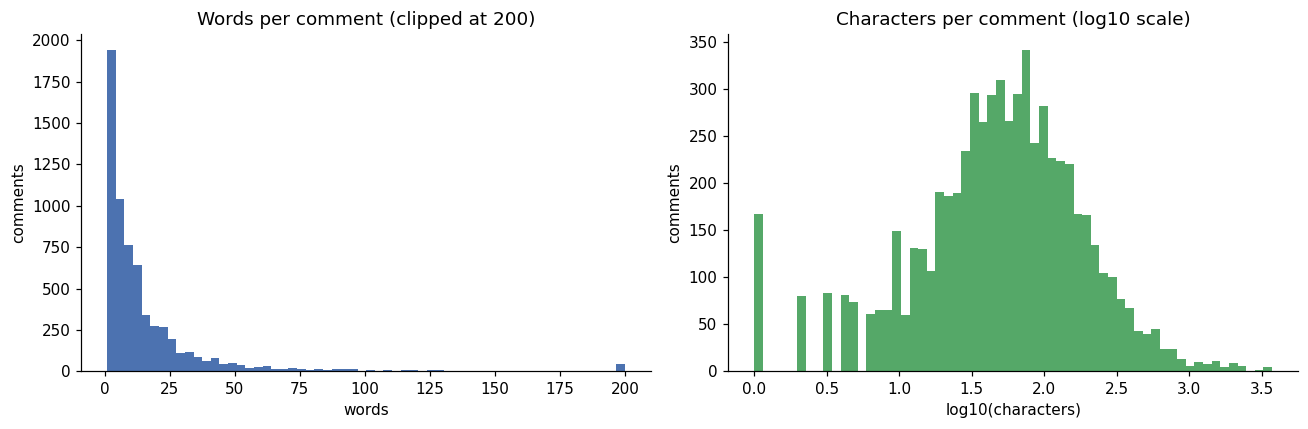

,n_words,n_chars
count,6368.0,6368.0
mean,16.7,106.9
std,31.9,205.7
min,1.0,1.0
25%,4.0,23.0
50%,8.0,53.0
75%,18.0,114.0
90%,36.0,228.3
99%,135.0,859.0
max,601.0,3717.0


Comments with <= 3 words: 1565 (24.6%)


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(corpus.n_words.clip(upper=200), bins=60, color='#4C72B0')
axes[0].set(title='Words per comment (clipped at 200)', xlabel='words', ylabel='comments')
axes[1].hist(np.log10(corpus.n_chars.clip(lower=1)), bins=60, color='#55A868')
axes[1].set(title='Characters per comment (log10 scale)', xlabel='log10(characters)', ylabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_length_hist.png', bbox_inches='tight'); plt.show()

display(corpus[['n_words', 'n_chars']].describe(percentiles=[.25, .5, .75, .9, .99]).round(1))
print('Comments with <= 3 words:', (corpus.n_words <= 3).sum(), f'({(corpus.n_words <= 3).mean():.1%})')

In [23]:
val = (corpus[corpus.lang_group.isin(['english', 'romanised_sinhala (singlish)'])]
       .groupby('lang_group', group_keys=False)
       .apply(lambda g: g.sample(min(50, len(g)), random_state=SEED))
       [['comment_id', 'text_original', 'lang_group']])
val['human_label'] = ''
val.to_csv(BASE_DIR / 'lang_validation.csv', index=False, encoding='utf-8-sig')
print('Open lang_validation.csv in Drive, fill human_label with english / singlish, save, then run the next cell')

/tmp/ipykernel_515/3813608817.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(50, len(g)), random_state=SEED))


Open lang_validation.csv in Drive, fill human_label with english / singlish, save, then run the next cell


In [24]:
val = pd.read_csv(BASE_DIR / 'lang_validation.csv')
# Ensure human_label is treated as string and filled with a default if empty
val['human_label'] = val['human_label'].fillna('').astype(str)
val['pred'] = val.lang_group.str.startswith('romanised').map({True: 'singlish', False: 'english'})
print('Detector accuracy on 100 hand-labelled comments:', (val.pred == val.human_label.str.strip().str.lower()).mean().round(3))
pd.crosstab(val.human_label, val.pred)

Detector accuracy on 100 hand-labelled comments: 0.0


pred,english,singlish
human_label,,
,50,50


### Length by language group

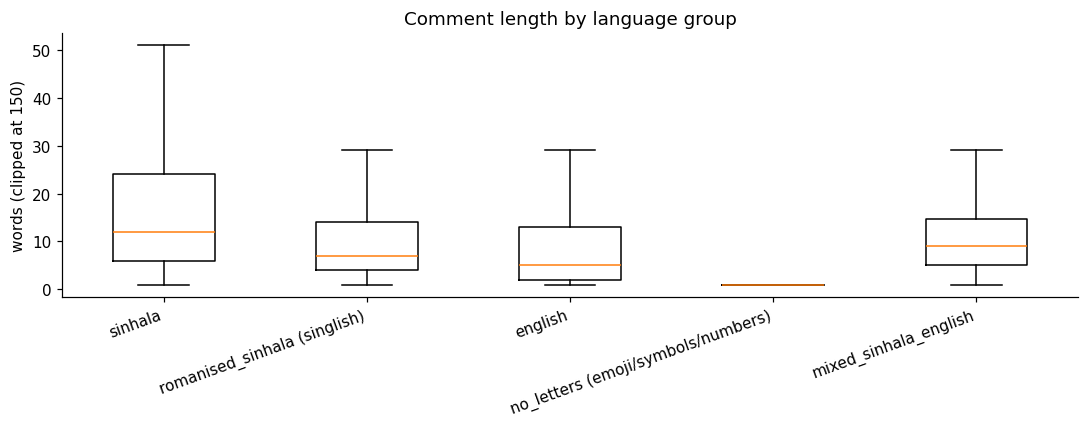

In [25]:
order = corpus.lang_group.value_counts().index
data = [corpus.loc[corpus.lang_group == g, 'n_words'].clip(upper=150) for g in order]
plt.figure(figsize=(10, 4))
plt.boxplot(data, showfliers=False)
plt.xticks(range(1, len(order) + 1), order, rotation=20, ha='right'); plt.ylabel('words (clipped at 150)')
plt.title('Comment length by language group')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_length_by_lang.png', bbox_inches='tight'); plt.show()

### Language distribution

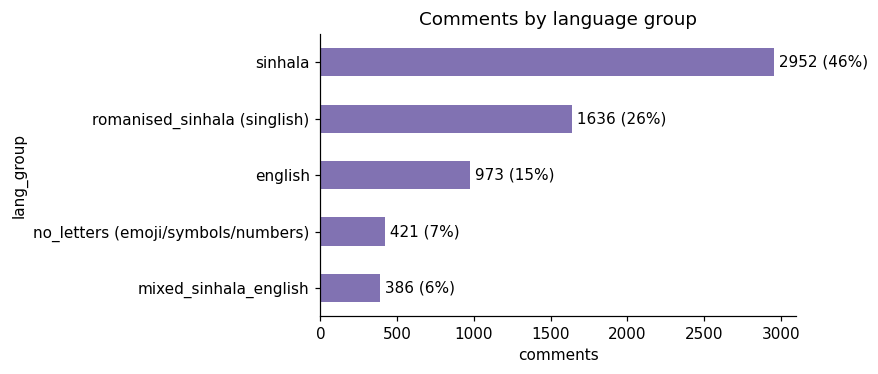

,text_original
lang_group,
english,"[Where do you live... not in sri lanka😂😂😂, Gon sajiya, do you know the difference between word and link? Link has sp..."
mixed_sinhala_english,"[Meya vitarai අනික් හැමෝම බූරුවන් අගමැති ජනපති නැතුව inne putthalam set, @nadeekaisuranga3974 ඔයා වගේද😅, Link eka ද..."
no_letters (emoji/symbols/numbers),"[😂, ❤🇱🇰, ❤❤❤❤❤]"
romanised_sinhala (singlish),[@BusinessPart-k4f5g egollo AL karalane ewa karanneth eka tibbath nathat AL hari thiyenawane. Apita AL chance eka na...
sinhala,"[1වසර 6වසර ව්තරක් නෙමෙයි.අනික් ළමයි ගැනත් හිතුවා නම් වට්නවා.ඔවුන් පීඩනයෙන් පරණ ව්දිහටම., අවුරුදු අද 18 ක විතර දරුව..."


In [26]:
lang_counts = corpus.lang_group.value_counts()
ax = lang_counts.plot.barh(figsize=(8, 3.5), color='#8172B2')
ax.invert_yaxis(); ax.set(title='Comments by language group', xlabel='comments')
for i, v in enumerate(lang_counts):
    ax.text(v, i, f' {v} ({v/len(corpus):.0%})', va='center')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_language.png', bbox_inches='tight'); plt.show()

# sample comments per group to sanity-check the detector
corpus.groupby('lang_group').text_original.apply(
    lambda s: s.sample(min(3, len(s)), random_state=SEED).tolist()).to_frame()

### Comments per video and per channel

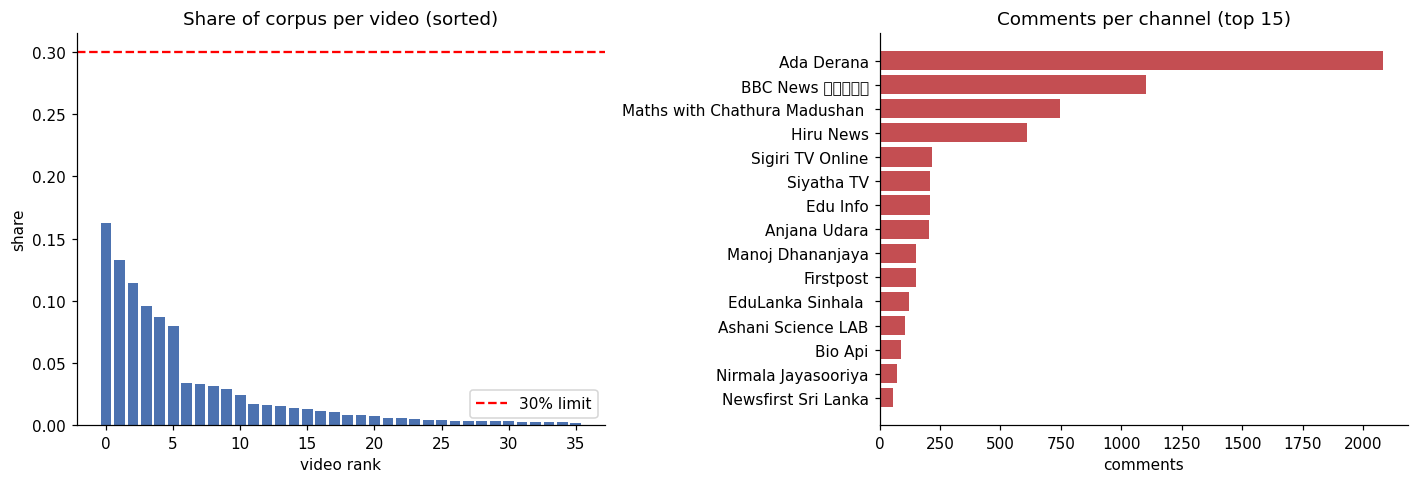

,video_id,channel_title,n,share
0,F-DLnJM7jpg,Ada Derana,1035,0.162531
1,RHfwHM3M9Fc,Ada Derana,845,0.132695
2,-pHFRz2p-Nw,Maths with Chathura Madushan,730,0.114636
3,iKJSiiynAWQ,Hiru News,610,0.095791
4,WoD8P9g8OHs,BBC News සිංහල,552,0.086683
5,Srr-sYiIDuI,BBC News සිංහල,510,0.080088
6,wq5d9IPRnfk,Sigiri TV Online,217,0.034077
7,mFrc4QiqAXE,Siyatha TV,210,0.032977
8,tHmwGBt4k74,Anjana Udara,203,0.031878
9,FKoS8yJOKWo,Edu Info,187,0.029366


In [27]:
per_video = corpus.groupby(['video_id', 'channel_title']).size().sort_values(ascending=False).reset_index(name='n')
per_video['share'] = per_video.n / len(corpus)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(len(per_video)), per_video.share, color='#4C72B0')
axes[0].axhline(MAX_VIDEO_SHARE, ls='--', c='red', label='30% limit')
axes[0].set(title='Share of corpus per video (sorted)', xlabel='video rank', ylabel='share'); axes[0].legend()

per_channel = corpus.channel_title.value_counts().head(15)
axes[1].barh(per_channel.index[::-1], per_channel.values[::-1], color='#C44E52')
axes[1].set(title='Comments per channel (top 15)', xlabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_per_video_channel.png', bbox_inches='tight'); plt.show()

per_video.head(10)

In [28]:
inc = videos[videos.include].sort_values('comment_count', ascending=False)
for _, v in inc.iterrows():
    sample = raw.loc[raw.video_id == v.video_id, 'text_original'].head(3).str.slice(0, 80).tolist()
    print(f"{v.video_id} | {v.channel_title} | {v.comment_count:.0f}\n   {v.title}\n   e.g. {sample}\n")

F-DLnJM7jpg | Ada Derana | 1030
   O/L, A/L සහ ශිෂ්‍යත්ව විභාගය ගැන දැනුම්දීමක් | Ada Derana
   e.g. ['Kimbi ammandi', 'wesagana puujita shreegabalpradha', '😂 ඔහොම හොදට ලයාන්විතව කතා කරාට මිනිහවත් බව කරන් ඇති']

RHfwHM3M9Fc | Ada Derana | 845
   අධ්‍යාපන ප්‍රතිසංස්කරණ ඇත්තටම අකුල ගත්තේ ඇයි | Ada Derana
   e.g. ['👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍❤❤❤❤❤❤❤❤❤❤', 'නලින්ද සහෝදරයා ඕවා අනිවාර්යයෙන්ම සංවාදයට ගත යුතුයි.\n❤❤❤', 'කොට කලිසම් ඇදගෙන දුවන පනින, උගුරු දණ්ඩවත් පැනලා නැත වයසකදි වෘත්තීය අධ්\u200dයාපනය තෝර']

-pHFRz2p-Nw | Maths with Chathura Madushan  | 728
   2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න
   e.g. ['මෙන්න අලුත් 6 වසර syllabus  එක👇👇👇👇👇👇👇👇👇👇\nhttps://youtu.be/InbNPEMbLgM', 'සමලිංගික විෂය නැද්ද', '2028 O/L අයටත් ඔක සෙට් වෙනවද']

iKJSiiynAWQ | Hiru News | 608
   2026 සිට අධ්‍යාපනයට වෙන්න යන වෙනස - Hiru News
   e.g. ['2012 ලමයින්ටයි හැම දාම අසාධාරනේ 5 වසරෙ පෙපර් 1,2 කොටස් මාරැ කරා දැන් පරන විදියට ', '2026 ol exame eka thiyenne

### Language mix per channel

In [29]:
pd.crosstab(corpus.channel_title, corpus.lang_group, margins=True).sort_values('All', ascending=False).head(12)

lang_group,english,mixed_sinhala_english,no_letters (emoji/symbols/numbers),romanised_sinhala (singlish),sinhala,All
channel_title,,,,,,
All,973,386,421,1636,2952,6368
Ada Derana,128,135,78,740,1001,2082
BBC News සිංහල,162,46,99,170,624,1101
Maths with Chathura Madushan,87,74,48,207,332,748
Hiru News,34,48,25,172,331,610
Sigiri TV Online,28,12,6,56,115,217
Siyatha TV,12,16,6,82,94,210
Edu Info,160,0,30,19,0,209
Anjana Udara,32,11,15,31,114,203


### Comments over time

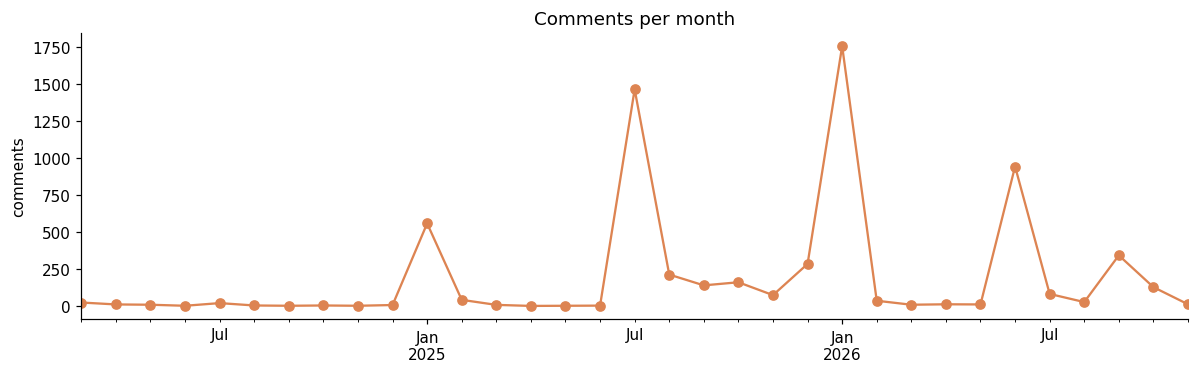

In [30]:
monthly = corpus.set_index('comment_published_at').resample('MS').size()
ax = monthly.plot(figsize=(11, 3.5), marker='o', color='#DD8452')
ax.set(title='Comments per month', xlabel='', ylabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_timeline.png', bbox_inches='tight'); plt.show()

### Top English words and word pairs (charts)

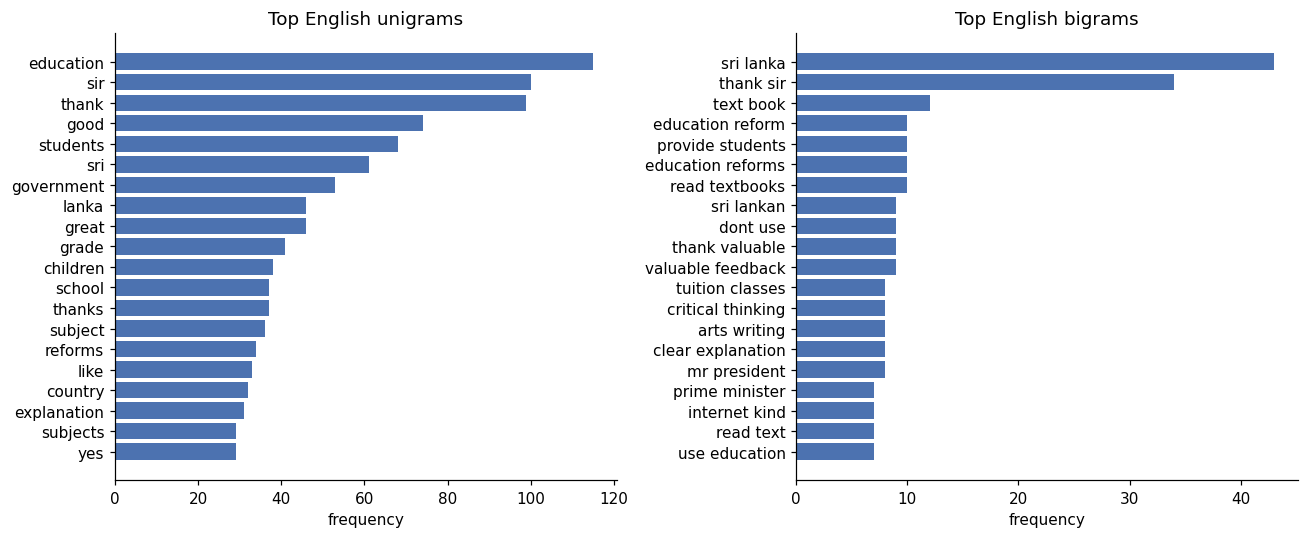

In [31]:
# EDA-only tokeniser: keeps Sinhala words whole, including vowel signs and the zero-width joiner (U+200D) in ශ්‍රී etc.
TOKEN_RE = re.compile(r"[\u0D80-\u0DFF\u200D]+|[a-z][a-z']+")
SI_STOP = {'සහ', 'හා', 'ද', 'නම්', 'ඒ', 'මේ', 'එක', 'එකක්', 'නෑ', 'නැහැ', 'කියලා', 'වගේ', 'තමයි', 'ඔයා', 'අපි', 'මම',
           'නිසා', 'තියෙන්නේ', 'ගැන', 'වෙන්න', 'කරන්න', 'එහෙම', 'මෙහෙම', 'තව', 'ඉතින්', 'හරි', 'නේ', 'ය', 'යි', 'වත්', 'දැන්'}
URL_RE = re.compile(r'https?://\S+|www\.\S+')
STOP = set(ENGLISH_STOP_WORDS) | SI_STOP | SINGLISH_MARKERS

def eda_tokens(text):
    t = URL_RE.sub(' ', str(text).lower())
    return [w for w in TOKEN_RE.findall(t) if w not in STOP and len(w) > 1]

def top_ngrams(texts, n=1, k=20):
    c = Counter()
    for t in texts:
        toks = eda_tokens(t)
        c.update(zip(*[toks[i:] for i in range(n)]))
    return pd.DataFrame([(' '.join(g), f) for g, f in c.most_common(k)], columns=['ngram', 'freq'])

groups = {'english': corpus.lang_group == 'english',
          'sinhala': corpus.lang_group == 'sinhala',
          'romanised_sinhala': corpus.lang_group.str.startswith('romanised'),
          'mixed': corpus.lang_group == 'mixed_sinhala_english'}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, n in zip(axes, (1, 2)):
    df_ng = top_ngrams(corpus.loc[groups['english'], 'text_original'], n=n)
    ax.barh(df_ng.ngram[::-1], df_ng.freq[::-1], color='#4C72B0')
    ax.set(title=f'Top English {"unigrams" if n == 1 else "bigrams"}', xlabel='frequency')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_english_ngrams.png', bbox_inches='tight'); plt.show()

### Top Sinhala / Singlish / mixed words (tables, because charts can't draw Sinhala letters properly)

In [32]:
tables = []
for g in ['sinhala', 'romanised_sinhala', 'mixed']:
    if groups[g].sum() == 0:
        continue
    for n in (1, 2):
        t = top_ngrams(corpus.loc[groups[g], 'text_original'], n=n, k=15)
        t.columns = pd.MultiIndex.from_product([[f'{g} {"uni" if n == 1 else "bi"}gram'], t.columns])
        tables.append(t)
pd.concat(tables, axis=1)

sinhala unigram               sinhala bigram       \
             ngram freq                   ngram freq   
0             නැති  263               ඉගෙන ගන්න   53   
1              කරන  255                උසස් පෙළ   38   
2             ගන්න  237  අධ්‍යාපන ප්‍රතිසංස්කරණ   37   
3         අධ්‍යාපන  229                 අපේ රටේ   29   
4               ඒක  222                පාසල් වල   29   
5             ඉන්න  216         අධ්‍යාපන ක්‍රමය   29   
6               ඕන  211              විය යුතුයි   26   
7              අපේ  210                වැඩ බැරි   26   
8              මේක  205     බැරි පොල්බුරුවෙකුගේ   24   
9               වල  204   පොල්බුරුවෙකුගේ විලාපය   24   
10             වලට  198              විලාපය මෙය   24   
11             එපා  198                මෙය කාලය   24   
12              ඔය  191             කාලය නාස්ති   24   
13           පාසල්  190          නාස්ති කිරීමක්   24   
14             රටේ  189            කිරීමක් පමණි   24   

   romanised_sinhala unigram      romanised_sinhala bigram      mixed unigram  \
                       ngram freq                    ngram freq         ngram   
0                         na  140            kisima rataka   30      syllabus   
1                      pissu   83              links danne   29       english   
2                        sir   71            mulinma buddy   28           එකට   
3                        dan   65                buddy net   28            ඒක   
4                        ane   62            thoge mulinma   27          exam   
5                         ne   62               net deepan   27           වලට   
6                    subject   60              deepan moda   27         අලුත්   
7                       rate   59              moda haraka   27           නේද   
8                       inna   57             haraka links   27           එකේ   
9                      danne   56             danne kisima   27       subject   
10                       epa   55           rataka thopita   27         grade   
11                      hari   55            thopita pissu   27         maths   
12                       ona   52              pissu unata   27       ඉතිහාසය   
13                       nam   52               unata rate   27            ඕන   
14                      moda   51            rate okkotama   27           තමා   

                mixed bigram       
   freq                ngram freq  
0    34       english medium   11  
1    28   maths withchathura    8  
2    25       අලුත් syllabus    8  
3    21             exam එකට    6  
4    20              වසරට යන    4  
5    20              ගන්න ඕන    4  
6    19  lucifer secretagent    4  
7    18              ජය වේවා    4  
8    18            වැඩක් ඇති    4  
9    17          npp germany    4  
10   17      comment section    4  
11   16            ඉගෙන ගන්න    3  
12   16            මේක බලන්න    3  
13   16       syllabus අලුත්    3  
14   16       syllabus grade    3